In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the original dataset again
df = pd.read_csv(
    "/kaggle/input/datasets/muhammedajmalvp/telco-customer-churn-csv/Telco-Customer-Churn.csv"
)

# Clean the data
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

df = df.dropna()

# Remove unnecessary customer ID
df = df.drop(columns=["customerID"], errors="ignore")

print("Dataset Reloaded Successfully!")
print("Shape:", df.shape)
print(df.head())

Dataset Reloaded Successfully!
Shape: (7032, 20)
   gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  Female              0     Yes         No       1           No   
1    Male              0      No         No      34          Yes   
2    Male              0      No         No       2          Yes   
3    Male              0      No         No      45           No   
4  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity OnlineBackup  \
0  No phone service             DSL             No          Yes   
1                No             DSL            Yes           No   
2                No             DSL            Yes          Yes   
3  No phone service             DSL            Yes           No   
4                No     Fiber optic             No           No   

  DeviceProtection TechSupport StreamingTV StreamingMovies        Contract  \
0               No          No          No              No  M

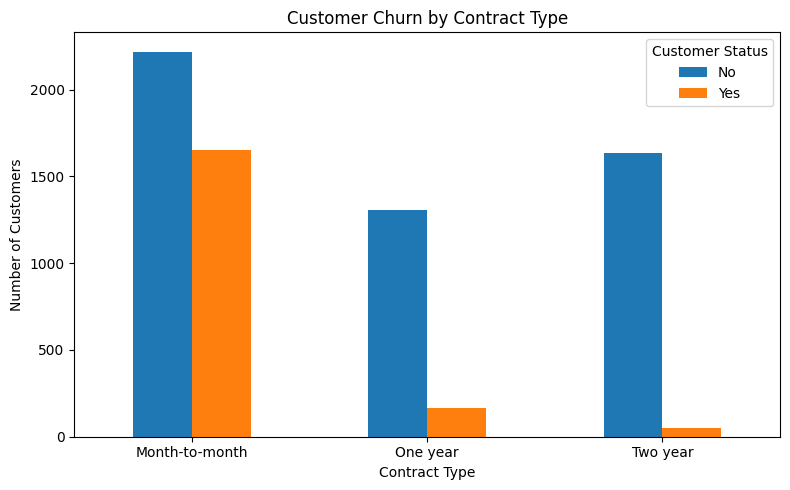

In [2]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"]
)

contract_churn.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.legend(title="Customer Status")
plt.tight_layout()
plt.show()

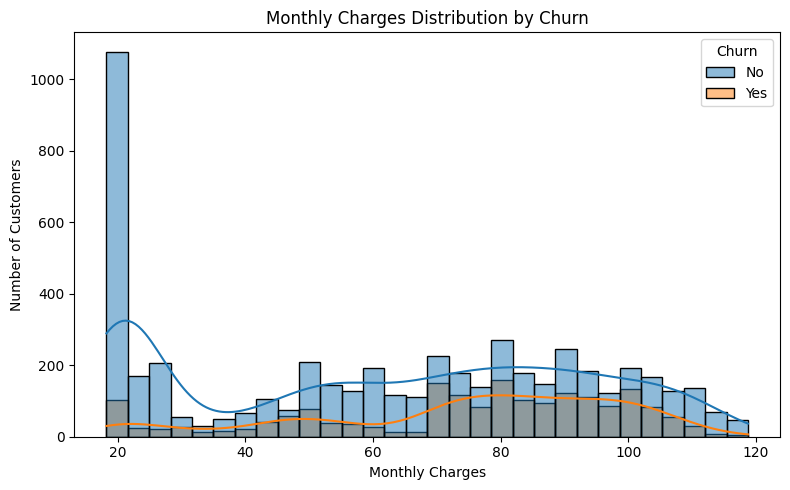

In [3]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="MonthlyCharges",
    hue="Churn",
    bins=30,
    kde=True
)

plt.title("Monthly Charges Distribution by Churn")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

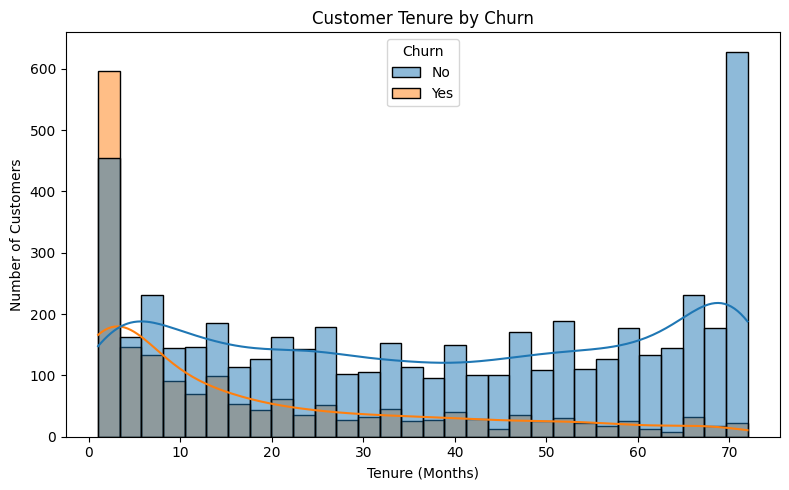

In [4]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="tenure",
    hue="Churn",
    bins=30,
    kde=True
)

plt.title("Customer Tenure by Churn")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Separate input features and target
X = df.drop("Churn", axis=1)
y = df["Churn"]

# Identify numerical and categorical columns
numerical_cols = X.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_cols = X.select_dtypes(
    include=["object"]
).columns

# Create preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            numerical_cols
        ),
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_cols
        )
    ]
)

print("Data Preprocessing Setup Completed!")
print("Numerical Columns:", len(numerical_cols))
print("Categorical Columns:", len(categorical_cols))

Data Preprocessing Setup Completed!
Numerical Columns: 4
Categorical Columns: 15


In [6]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train/Test Split Completed!")
print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)
print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Train/Test Split Completed!
Training Data Shape: (5625, 19)
Testing Data Shape: (1407, 19)
Training Target Shape: (5625,)
Testing Target Shape: (1407,)


In [7]:
# Create Logistic Regression Model

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train the model
model.fit(X_train, y_train)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [8]:
# Predict on test data
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

# Display classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 80.38 %

Classification Report:
              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1033
         Yes       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



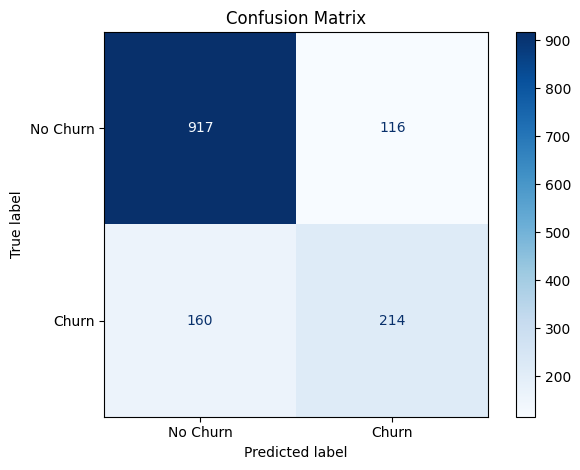

In [9]:
# Create Confusion Matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["No", "Yes"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot(cmap="Blues")

plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

In [10]:
# Select one customer from the test dataset
sample_customer = X_test.iloc[[0]]

# Predict customer churn
prediction = model.predict(sample_customer)

# Calculate prediction probabilities
probability = model.predict_proba(sample_customer)[0]

# Get probability of churn
churn_index = list(model.classes_).index("Yes")
churn_probability = probability[churn_index] * 100

print("Final Customer Churn Prediction")
print("--------------------------------")
print("Predicted Status:", prediction[0])
print("Churn Probability:", round(churn_probability, 2), "%")

if prediction[0] == "Yes":
    print("Result: Customer is likely to Churn.")
else:
    print("Result: Customer is likely to Stay.")

Final Customer Churn Prediction
--------------------------------
Predicted Status: No
Churn Probability: 1.75 %
Result: Customer is likely to Stay.
